# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
numbers = list(range(10))  # список для shuffle

print("До seed:", random.randint(1, 100))
random.shuffle(numbers)
print("До seed (shuffle):", numbers)

set_seed()
print("Seed зафіксовано:", SEED)

set_seed()
r1 = random.randint(1, 100)
set_seed()
r2 = random.randint(1, 100)
print(f"З повторним set_seed(): {r1} і {r2}")

r3 = random.randint(1, 100)
r4 = random.randint(1, 100)
print(f"Без проміжного set_seed(): {r3} і {r4}")

До seed: 18
До seed (shuffle): [2, 0, 5, 4, 8, 6, 9, 1, 7, 3]
Seed зафіксовано: 42
З повторним set_seed(): 82 і 82
Без проміжного set_seed(): 15 і 4


set_seed() скидає генератор псевдовипадкових чисел у початковий детермінований стан. Якщо перед кожною генерацією викликати set_seed(), послідовність згенерованих чисел буде точним дублікатом. Якщо генерація відбувається послідовно без проміжного скидання, кожне наступне число буде відрізнятися від попереднього, але вся послідовність залишатиметься відтворюваною від запуску до запуску.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [11]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print("Zeros array:\n", zeros_arr, "\nShape:", zeros_arr.shape, "| Type:", zeros_arr.dtype)
print("\nSevens array:\n", sevens_arr, "\nShape:", sevens_arr.shape, "| Type:", sevens_arr.dtype)

Zeros array:
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] 
Shape: (3, 4) | Type: float64

Sevens array:
 [[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] 
Shape: (3, 4) | Type: int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [12]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)
print("Arange:", arange_arr)
print("Linspace:", linspace_arr)


Arange: [ 0  2  4  6  8 10 12 14 16 18]
Linspace: [0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [13]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))
print("Identity ndim:", identity.ndim)
print("Random ints ndim:", random_ints.ndim)

Identity ndim: 2
Random ints ndim: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [14]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])
mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std
print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)

Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [15]:
arr = np.arange(1, 13)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)
print("Matrix:\n", matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)

Matrix:
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [17]:
data = {
    "name": ["Софія", "Міша", "Іван", "Олена", "Тарас"],
    "score": [78, 95, 82, 67, 90]
}
df = pd.DataFrame(data)
top = df[df["score"] > 80].sort_values(by="score", ascending=False)
print(top)


    name  score
1   Міша     95
4  Тарас     90
2   Іван     82


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [18]:
conditions = [
    df["score"] >= 90,
    df["score"] >= 75
]
choices = ["A", "B"]
df["grade"] = np.select(conditions, choices, default="C")
print(df)

    name  score grade
0  Софія     78     B
1   Міша     95     A
2   Іван     82     B
3  Олена     67     C
4  Тарас     90     A


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [19]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)
print(zeros_t, zeros_t.shape, zeros_t.dtype)
print(sevens_t, sevens_t.shape, sevens_t.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [20]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)
print(arange_t)
print(linspace_t)

tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [21]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)
print(from_list.shape, from_list.dtype, from_list.ndim)
print(random_t.shape, random_t.dtype, random_t.ndim)

torch.Size([2, 2]) torch.int64 2
torch.Size([3, 3]) torch.float32 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [22]:
n = 5.0
x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()
print("Обчислений градієнт:", x.grad.item())
print("Аналітичний градієнт (2*n):", 2 * n)

Обчислений градієнт: 10.0
Аналітичний градієнт (2*n): 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [23]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for epoch in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")

x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

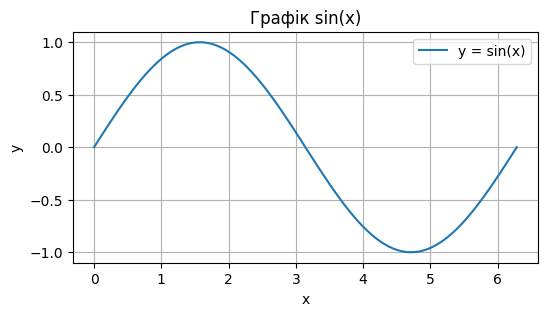

In [24]:
xs = np.linspace(0, 2 * np.pi, 100)
plt.figure(figsize=(6, 3))
plt.plot(xs, np.sin(xs), label="y = sin(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Графік sin(x)")
plt.legend()
plt.grid(True)
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

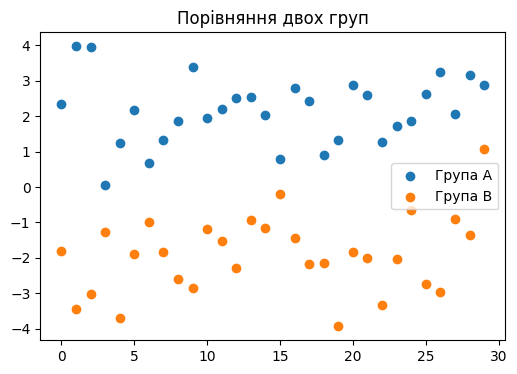

In [27]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.figure(figsize=(6, 4))
plt.scatter(range(30), group_a, color="C0", label="Група A")
plt.scatter(range(30), group_b, color="C1", label="Група B")
plt.title("Порівняння двох груп")
plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [28]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

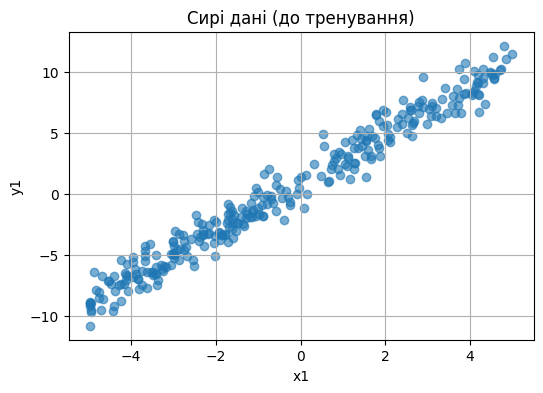

In [29]:
plt.figure(figsize=(6, 4))
plt.scatter(x1.numpy(), y1.numpy(), alpha=0.6)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.grid(True)
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [31]:
indices = torch.randperm(TASK1_N)
train_size = int(0.70 * TASK1_N)
val_size = int(0.15 * TASK1_N)

train_idx = indices[:train_size]
val_idx = indices[train_size:train_size + val_size]
test_idx = indices[train_size + val_size:]

x_train1, y_train1 = x1[train_idx], y1[train_idx]
x_val1, y_val1 = x1[val_idx], y1[val_idx]
x_test1, y_test1 = x1[test_idx], y1[test_idx]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [32]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=44.691837  w=1.6024 (true 2.0)  b=0.5393 (true 1.0)
epoch   30  loss=1.035348  w=1.9740 (true 2.0)  b=0.9998 (true 1.0)
epoch   60  loss=1.034686  w=1.9754 (true 2.0)  b=1.0222 (true 1.0)
epoch   90  loss=1.034685  w=1.9755 (true 2.0)  b=1.0233 (true 1.0)
epoch   99  loss=1.034685  w=1.9755 (true 2.0)  b=1.0233 (true 1.0)


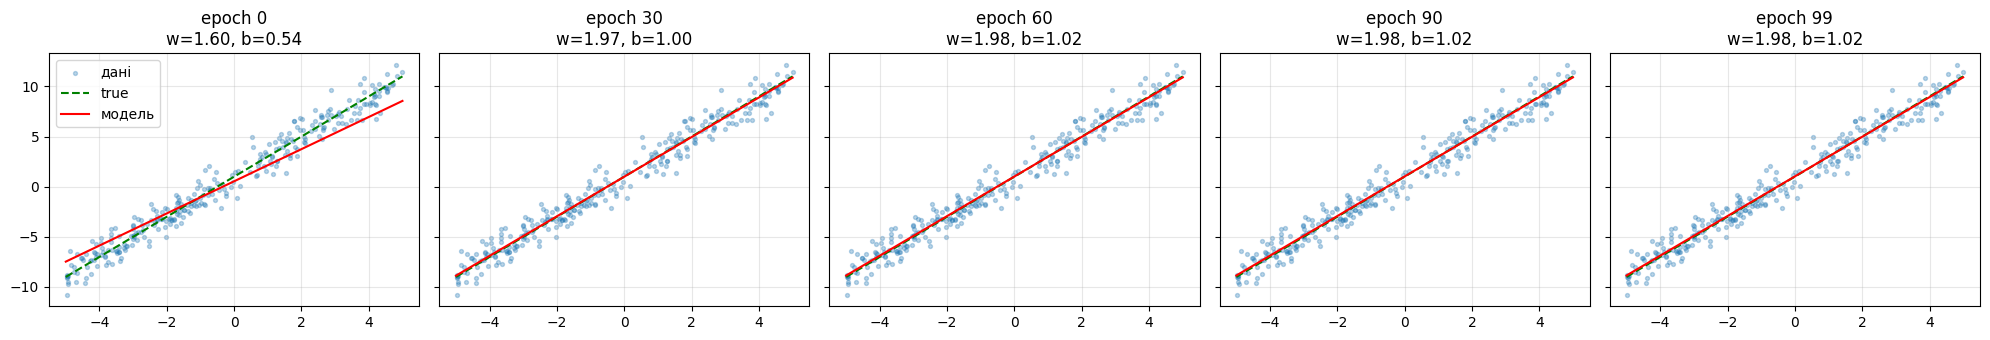

In [33]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

Сценарій:

Прогноз вартості поїздки на таксі ($y$, грн) залежно від відстані ($x$, км).

Залежність: $w = 12.0$ (ціна за 1 км), $b = 40.0$ (посадка / подача авто).

Обґрунтування: Базова вартість виклику таксі становить 40 грн, а кожен кілометр шляху додає до чека 12 грн. Невеликий шум враховує простої у заторах.

In [34]:
import os
import torch
import torch.nn as nn
import pandas as pd

# 1. Фіксуємо випадковість
set_seed()

# 2. Генерація даних
N_SAMPLES = 200
TRUE_W = 12.0  # 12 грн за 1 км
TRUE_B = 40.0  # 40 грн за посадку

km = torch.empty(N_SAMPLES, 1).uniform_(1, 25)  # відстань від 1 до 25 км
noise = torch.randn(N_SAMPLES, 1) * 5.0        # шум (затори, світлофори)
price = TRUE_W * km + TRUE_B + noise

# Збереження датасету у CSV файл
df_taxi = pd.DataFrame({
    "distance_km": km.squeeze().tolist(),
    "price_uah": price.squeeze().tolist()
})
df_taxi.to_csv("dataset.csv", index=False)
df_taxi.to_csv(os.path.join(ARTIFACT_DIR, "dataset.csv"), index=False)
print("Датасет успішно збережено у dataset.csv")

# 3. Розбиття на train/val/test (70/15/15)
perm = torch.randperm(N_SAMPLES)
t_size, v_size = int(0.7 * N_SAMPLES), int(0.15 * N_SAMPLES)

x_tr, y_tr = km[perm[:t_size]], price[perm[:t_size]]
x_va, y_va = km[perm[t_size:t_size+v_size]], price[perm[t_size:t_size+v_size]]
x_te, y_te = km[perm[t_size+v_size:]], price[perm[t_size+v_size:]]

# 4. Створення та тренування лінійної регресії
model = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

for epoch in range(400):
    model.train()
    pred = model(x_tr)
    loss = criterion(pred, y_tr)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# Перевірка на тестових даних
model.eval()
with torch.no_grad():
    test_loss = criterion(model(x_te), y_te).item()

print(f"Навчання завершено! Тестовий MSE Loss: {test_loss:.4f}")

Датасет успішно збережено у dataset.csv
Навчання завершено! Тестовий MSE Loss: 120.6724


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [35]:
torch.save(model.state_dict(), "model.pt")
torch.save(model.state_dict(), os.path.join(ARTIFACT_DIR, "model.pt"))

print("Модель успішно збережена у файлі model.pt!")

Модель успішно збережена у файлі model.pt!


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [36]:
import gradio as gr

loaded_model = nn.Linear(1, 1)
loaded_model.load_state_dict(torch.load("model.pt"))
loaded_model.eval()

def predict_taxi_price(distance):
    input_val = torch.tensor([[float(distance)]], dtype=torch.float32)
    with torch.no_grad():
        res = loaded_model(input_val).item()
    return f"{res:.1f} грн"

demo = gr.Interface(
    fn=predict_taxi_price,
    inputs=gr.Number(label="Відстань поїздки (км)"),
    outputs=gr.Textbox(label="Розрахована вартість поїздки"),
    title="Калькулятор вартості таксі"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5d67b111deeb141bd2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```